# WaterWise
## Data-Driven Urban Water Network Analysis and Fault-Proximity Classification

### Project overview
WaterWise explores hourly water-network-related sensor, energy, and environmental anomaly-score data. The notebook cleans the dataset, studies distributions and trends, compares observations by the supplied `fault_d7` label, and evaluates two classification models.

**Important interpretation:** `fault_d7` is the dataset's label for being within a defined ±7-day fault-proximity window. A model prediction is an estimate of this dataset label—not confirmation of a physical leak, a real-time alarm, or a causal explanation.

### Project workflow
1. Load and inspect the data
2. Clean timestamps and missing values
3. Explore the target and descriptive statistics
4. Visualize distributions, outliers, trends, group comparisons, and correlations
5. Create time-based features
6. Split chronologically into training and test sets
7. Train Logistic Regression and Random Forest
8. Evaluate class-wise performance and inspect feature importance
9. Save models for a future Streamlit dashboard

### Research questions
- What data-quality issues are present in the dataset?
- How do selected sensor, energy, and environmental variables vary over time?
- Do selected variables show different averages across fault-proximity label groups?
- How do two baseline classifiers compare on later observations?

## 1. Import Libraries
Load the libraries used for tabular data handling, numerical operations, and plotting.

In [ ]:
# WaterWise
# Intelligent Urban Water Management & Anomaly Analytics

#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Upload the Dataset
Upload the CSV supplied for the project. Keep the original dataset file available so the notebook can be rerun.

In [ ]:
#Upload the CSV
from google.colab import files

uploaded = files.upload()

Saving input_model_potenc_predXfault7_A.csv to input_model_potenc_predXfault7_A.csv


## 3. Load the Dataset
Read the uploaded CSV into a pandas DataFrame and confirm the dimensions.

In [ ]:
#Load the uploaded CSV
import io

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (8737, 20)


## 4. Initial Dataset Overview
Inspect the row count, column count, and column names before analysis.

In [ ]:
# Basic dataset overview

print("WaterWise Dataset Overview")
print("-" * 40)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

WaterWise Dataset Overview
----------------------------------------
Rows: 8737
Columns: 20

Column names:
['timestamp', 'fault_d7', '4700008966_kW', '4700008966_power_hour', '4408411600_kW', '4408411600_power_hour', '4608927500_kvar_hour', '238045_ws_temp', '279805_ws_vigor', '279804_ws_level', '279625_ws_temp', '279623_ws_vigor', '319235_ws_temp', '279831_ws_temp', '326417_ws_temp', '326416_ws_vigor', 'temp_site1_anomaly_score', 'sfc_temp_site1_anomaly_score', 'gw_lvl_site2_anomaly_score', 'gw_temp_site2_anomaly_score']


In [ ]:
df.head()

,timestamp,fault_d7,4700008966_kW,4700008966_power_hour,4408411600_kW,4408411600_power_hour,4608927500_kvar_hour,238045_ws_temp,279805_ws_vigor,279804_ws_level,279625_ws_temp,279623_ws_vigor,319235_ws_temp,279831_ws_temp,326417_ws_temp,326416_ws_vigor,temp_site1_anomaly_score,sfc_temp_site1_anomaly_score,gw_lvl_site2_anomaly_score,gw_temp_site2_anomaly_score
0,31-12-2021 23:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-01-2022 0:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.34,7.63,9.48,38.44
2,01-01-2022 1:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.96,0.87,9.48,38.44
3,01-01-2022 2:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.01,1.23,9.48,38.44
4,01-01-2022 3:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.51,4.86,9.48,38.44


In [ ]:
df.tail()

,timestamp,fault_d7,4700008966_kW,4700008966_power_hour,4408411600_kW,4408411600_power_hour,4608927500_kvar_hour,238045_ws_temp,279805_ws_vigor,279804_ws_level,279625_ws_temp,279623_ws_vigor,319235_ws_temp,279831_ws_temp,326417_ws_temp,326416_ws_vigor,temp_site1_anomaly_score,sfc_temp_site1_anomaly_score,gw_lvl_site2_anomaly_score,gw_temp_site2_anomaly_score
8732,30-12-2022 19:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.36845,3.97,3.65,NaN,NaN
8733,30-12-2022 20:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.36845,4.67,6.97,NaN,NaN
8734,30-12-2022 21:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.36845,4.60,4.88,NaN,NaN
8735,30-12-2022 22:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.36845,6.74,6.56,NaN,NaN
8736,30-12-2022 23:00,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.36845,6.24,3.72,NaN,NaN


## 5. Data Types and Missing-Value Audit
Check data types and quantify missing values. Missing values are not automatically errors; their extent and meaning should guide the treatment.

In [ ]:
#Data types and missing values
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Data Types:
timestamp                        object
fault_d7                          int64
4700008966_kW                   float64
4700008966_power_hour           float64
4408411600_kW                   float64
4408411600_power_hour           float64
4608927500_kvar_hour            float64
238045_ws_temp                  float64
279805_ws_vigor                 float64
279804_ws_level                 float64
279625_ws_temp                  float64
279623_ws_vigor                 float64
319235_ws_temp                  float64
279831_ws_temp                  float64
326417_ws_temp                  float64
326416_ws_vigor                 float64
temp_site1_anomaly_score        float64
sfc_temp_site1_anomaly_score    float64
gw_lvl_site2_anomaly_score      float64
gw_temp_site2_anomaly_score     float64
dtype: object

Missing Values:
timestamp                          0
fault_d7                           0
4700008966_kW                      0
4700008966_power_hour              0
440841160

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8737 entries, 0 to 8736
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   timestamp                     8737 non-null   object 
 1   fault_d7                      8737 non-null   int64  
 2   4700008966_kW                 8737 non-null   float64
 3   4700008966_power_hour         8737 non-null   float64
 4   4408411600_kW                 6578 non-null   float64
 5   4408411600_power_hour         6578 non-null   float64
 6   4608927500_kvar_hour          8737 non-null   float64
 7   238045_ws_temp                8737 non-null   float64
 8   279805_ws_vigor               8724 non-null   float64
 9   279804_ws_level               8724 non-null   float64
 10  279625_ws_temp                8256 non-null   float64
 11  279623_ws_vigor               8256 non-null   float64
 12  319235_ws_temp                8700 non-null   float64
 13  279

## 6. Timestamp Preparation
Convert the timestamp to a datetime type and sort chronologically. This is essential for time-series plots and a time-aware train/test split.

In [ ]:
#Convert Timestamp
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    format="%d-%m-%Y %H:%M"
)

df = df.sort_values("timestamp").reset_index(drop=True)

print("Timestamp converted successfully.")
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

Timestamp converted successfully.
Start: 2021-12-31 23:00:00
End: 2022-12-30 23:00:00


## 7. Duplicate Checks
Check duplicate rows and timestamps. The output should be reviewed before deciding whether any records need to be removed.

In [ ]:
#Check Duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

Duplicate rows: 0
Duplicate timestamps: 0


## 8. Visualize Missingness
Plot the percentage of missing values by feature to make sparse columns easy to identify.

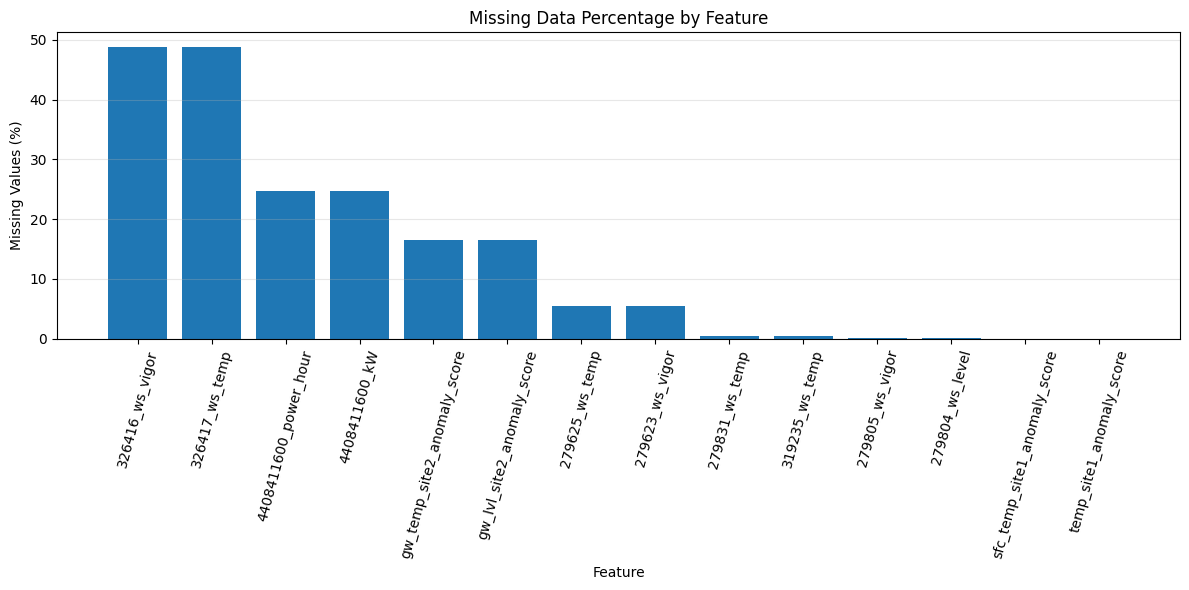

In [ ]:
#Misiing Value Visulaization
missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[missing_percent > 0]

plt.figure(figsize=(12, 6))

plt.bar(
    missing_percent.index,
    missing_percent.values
)

plt.title("Missing Data Percentage by Feature")
plt.xlabel("Feature")
plt.ylabel("Missing Values (%)")

plt.xticks(rotation=75)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Handle Missing Values
The current rule removes numeric columns with more than 40% missing values and median-imputes the remaining numeric columns. This is a pragmatic project choice; mention it in the report and note that median imputation can smooth genuine unusual readings.

In [ ]:
#Handle missing values
# Keep the original dataset unchanged
df_clean = df.copy()

# Identify numeric columns
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

# Drop extremely sparse sensor columns
high_missing_cols = [
    col for col in numeric_cols
    if df_clean[col].isnull().mean() > 0.40
]

print("Columns removed due to >40% missing data:")
print(high_missing_cols)

df_clean = df_clean.drop(columns=high_missing_cols)

# Fill remaining numeric missing values with median
remaining_numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

for col in remaining_numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

print("\nRemaining missing values:")
print(df_clean.isnull().sum().sum())

print("\nClean dataset shape:", df_clean.shape)

Columns removed due to >40% missing data:
['326417_ws_temp', '326416_ws_vigor']

Remaining missing values:
0

Clean dataset shape: (8737, 18)


## 10. Descriptive Statistics
Review count, mean, standard deviation, quartiles, and range. Skewed distributions and extreme values are common in operational and anomaly-score data.

In [ ]:
#Descriptive statistics
df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,8737,2022-07-01 23:00:00,2021-12-31 23:00:00,2022-04-01 23:00:00,2022-07-01 23:00:00,2022-09-30 23:00:00,2022-12-30 23:00:00,NaN
fault_d7,8737.0,0.736179,0.0,0.0,1.0,1.0,1.0,0.440728
4700008966_kW,8737.0,1.235631,0.0,0.0,0.0,0.0,99.07577,8.653457
4700008966_power_hour,8737.0,1.229322,0.0,0.0,0.0,0.0,99.07577,8.622856
4408411600_kW,8737.0,0.141556,0.0,0.0,0.0,0.0,94.83913,2.707001
4408411600_power_hour,8737.0,0.251249,0.0,0.0,0.0,0.0,97.25242,3.727705
4608927500_kvar_hour,8737.0,0.495424,0.0,0.0,0.0,0.0,99.005875,5.706254
238045_ws_temp,8737.0,0.109122,0.0,0.0,0.0,0.0,95.76311,2.180266
279805_ws_vigor,8737.0,0.864857,0.0,0.0,0.0,0.0,91.95816,6.217987
279804_ws_level,8737.0,0.366883,0.0,0.0,0.0,0.0,85.68549,4.784654


## 11. Target Label Distribution
Count the examples in each `fault_d7` class. This is important because class imbalance can make accuracy alone misleading.

In [ ]:
#Target Distribution
target_counts = df_clean["fault_d7"].value_counts()

print(target_counts)

fault_d7
1    6432
0    2305
Name: count, dtype: int64


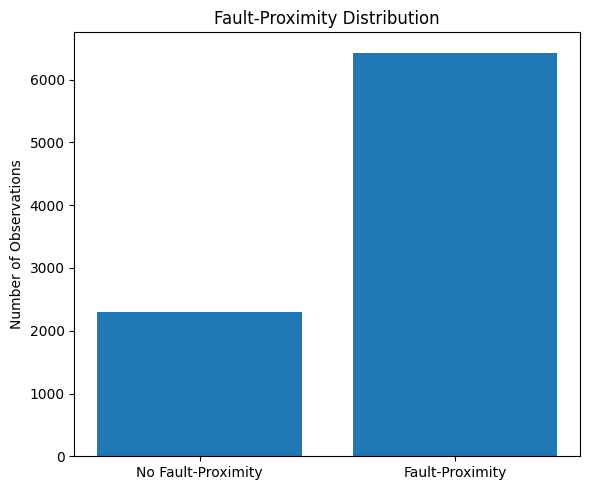

In [ ]:
plt.figure(figsize=(6, 5))

plt.bar(
    ["No Fault-Proximity", "Fault-Proximity"],
    [
        target_counts.get(0, 0),
        target_counts.get(1, 0)
    ]
)

plt.title("Fault-Proximity Distribution")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

## 12. Final Cleaned Dataset
Remove temporary analysis helpers, then confirm the final dimensions and columns.

In [ ]:
# Remove analysis helper columns
df_clean = df_clean.drop(
    columns=["time_gap", "fault_group"],
    errors="ignore"
)

print("Final clean dataset shape:", df_clean.shape)

print("\nFinal columns:")
for i, col in enumerate(df_clean.columns, 1):
    print(f"{i}. {col}")

Final clean dataset shape: (8737, 18)

Final columns:
1. timestamp
2. fault_d7
3. 4700008966_kW
4. 4700008966_power_hour
5. 4408411600_kW
6. 4408411600_power_hour
7. 4608927500_kvar_hour
8. 238045_ws_temp
9. 279805_ws_vigor
10. 279804_ws_level
11. 279625_ws_temp
12. 279623_ws_vigor
13. 319235_ws_temp
14. 279831_ws_temp
15. temp_site1_anomaly_score
16. sfc_temp_site1_anomaly_score
17. gw_lvl_site2_anomaly_score
18. gw_temp_site2_anomaly_score


## 13. Exploratory Data Analysis (EDA)
EDA helps understand the shape, spread, relationships, and temporal behavior of the variables before modeling.

In [ ]:
#EDA

In [ ]:
# Descriptive statistics of the cleaned dataset

df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,8737,2022-07-01 23:00:00,2021-12-31 23:00:00,2022-04-01 23:00:00,2022-07-01 23:00:00,2022-09-30 23:00:00,2022-12-30 23:00:00,NaN
fault_d7,8737.0,0.736179,0.0,0.0,1.0,1.0,1.0,0.440728
4700008966_kW,8737.0,1.235631,0.0,0.0,0.0,0.0,99.07577,8.653457
4700008966_power_hour,8737.0,1.229322,0.0,0.0,0.0,0.0,99.07577,8.622856
4408411600_kW,8737.0,0.141556,0.0,0.0,0.0,0.0,94.83913,2.707001
4408411600_power_hour,8737.0,0.251249,0.0,0.0,0.0,0.0,97.25242,3.727705
4608927500_kvar_hour,8737.0,0.495424,0.0,0.0,0.0,0.0,99.005875,5.706254
238045_ws_temp,8737.0,0.109122,0.0,0.0,0.0,0.0,95.76311,2.180266
279805_ws_vigor,8737.0,0.864857,0.0,0.0,0.0,0.0,91.95816,6.217987
279804_ws_level,8737.0,0.366883,0.0,0.0,0.0,0.0,85.68549,4.784654


### 13.1 Select Representative Features
The selected columns cover energy/operational readings, water-system sensor readings, and environmental anomaly scores. They are a manageable subset for readable visualizations.

In [ ]:
#Select main numerical features
# Select representative variables for EDA

eda_features = [
    "4700008966_kW",
    "4700008966_power_hour",
    "4408411600_kW",
    "279805_ws_vigor",
    "279804_ws_level",
    "temp_site1_anomaly_score",
    "sfc_temp_site1_anomaly_score",
    "gw_lvl_site2_anomaly_score",
    "gw_temp_site2_anomaly_score"
]

print("Selected EDA features:")
for i, col in enumerate(eda_features, 1):
    print(f"{i}. {col}")

Selected EDA features:
1. 4700008966_kW
2. 4700008966_power_hour
3. 4408411600_kW
4. 279805_ws_vigor
5. 279804_ws_level
6. temp_site1_anomaly_score
7. sfc_temp_site1_anomaly_score
8. gw_lvl_site2_anomaly_score
9. gw_temp_site2_anomaly_score


In [ ]:
#Why these 9?
#They give us a reasonable cross-section of:
#⚡ Energy/operational behavior
#💧 Water-system sensor behavior
#🌡️ Environmental anomaly behavior

### 13.2 Distribution Histograms
Histograms show how values are distributed. Look for skewness, piles of zeros, and long tails.

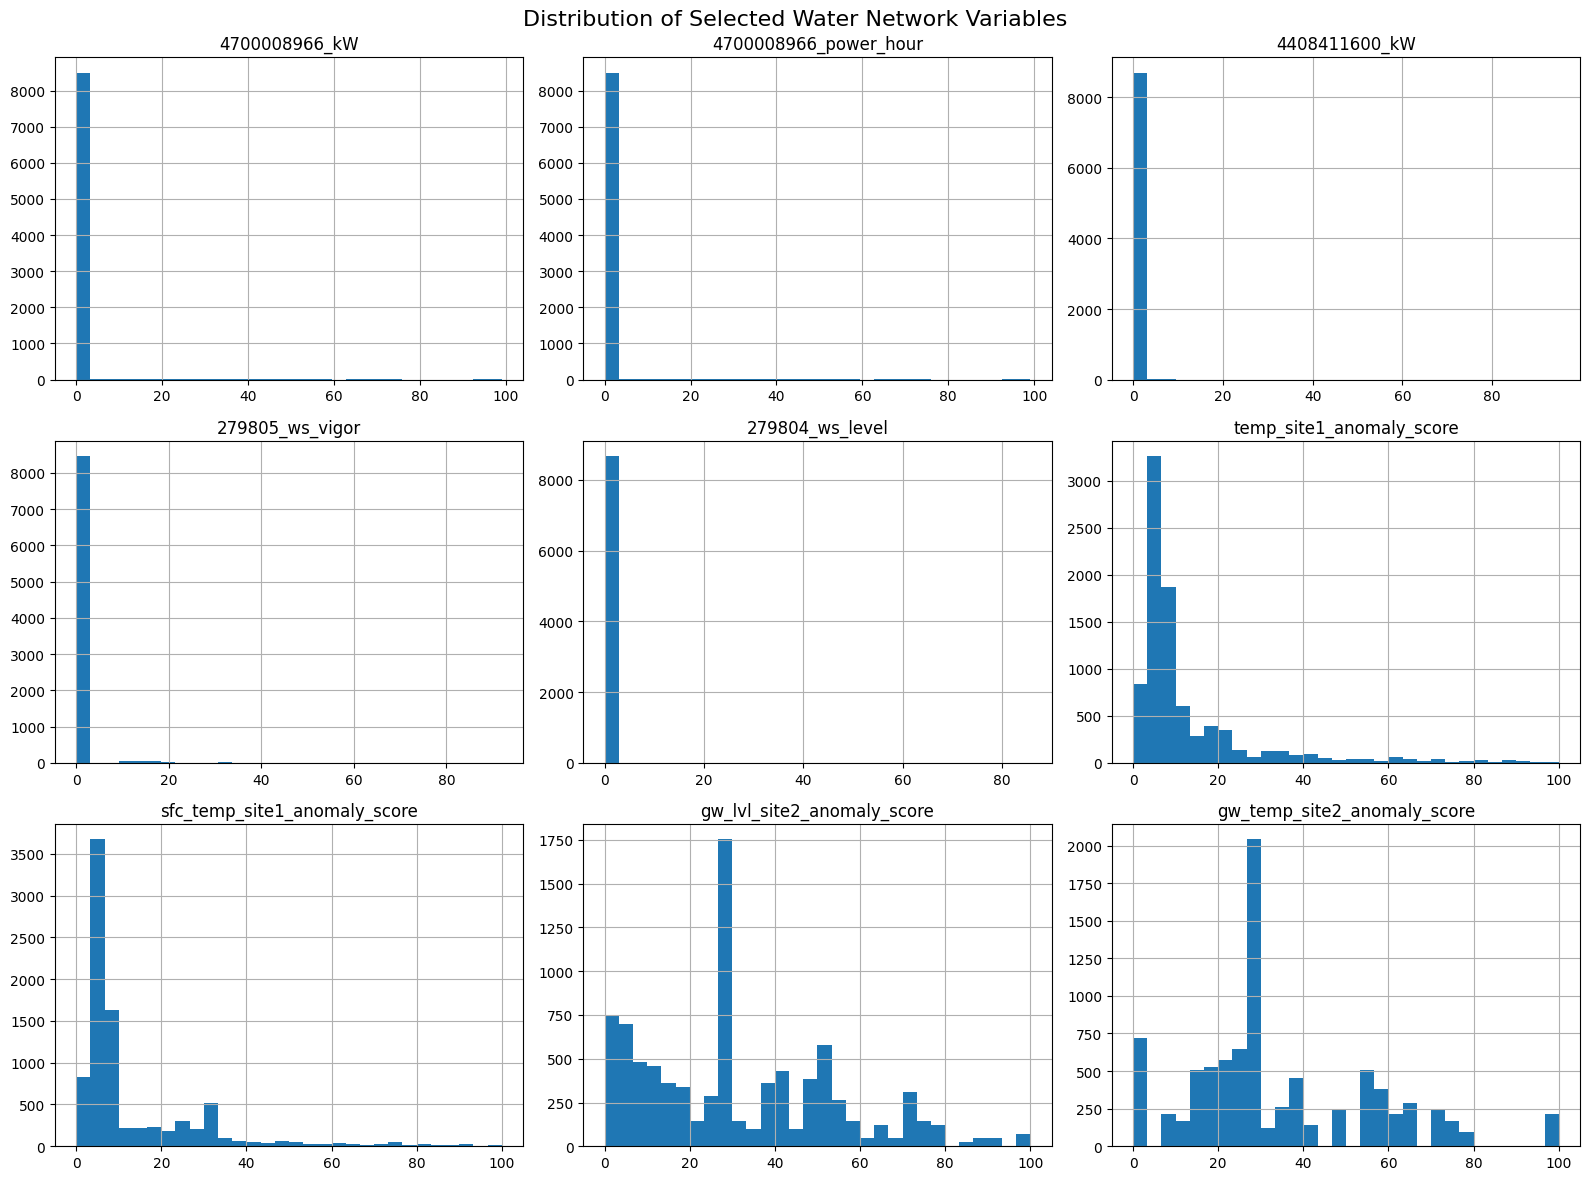

In [ ]:
#Distribution analysis
import matplotlib.pyplot as plt

# Plot distributions of selected EDA features
df_clean[eda_features].hist(
    bins=30,
    figsize=(16, 12)
)

plt.suptitle("Distribution of Selected Water Network Variables", fontsize=16)
plt.tight_layout()
plt.show()

### 13.3 Boxplots and Extreme Values
Boxplots highlight spread and potential extreme values. Do not automatically remove extremes: unusual values may be meaningful in anomaly-analysis data.

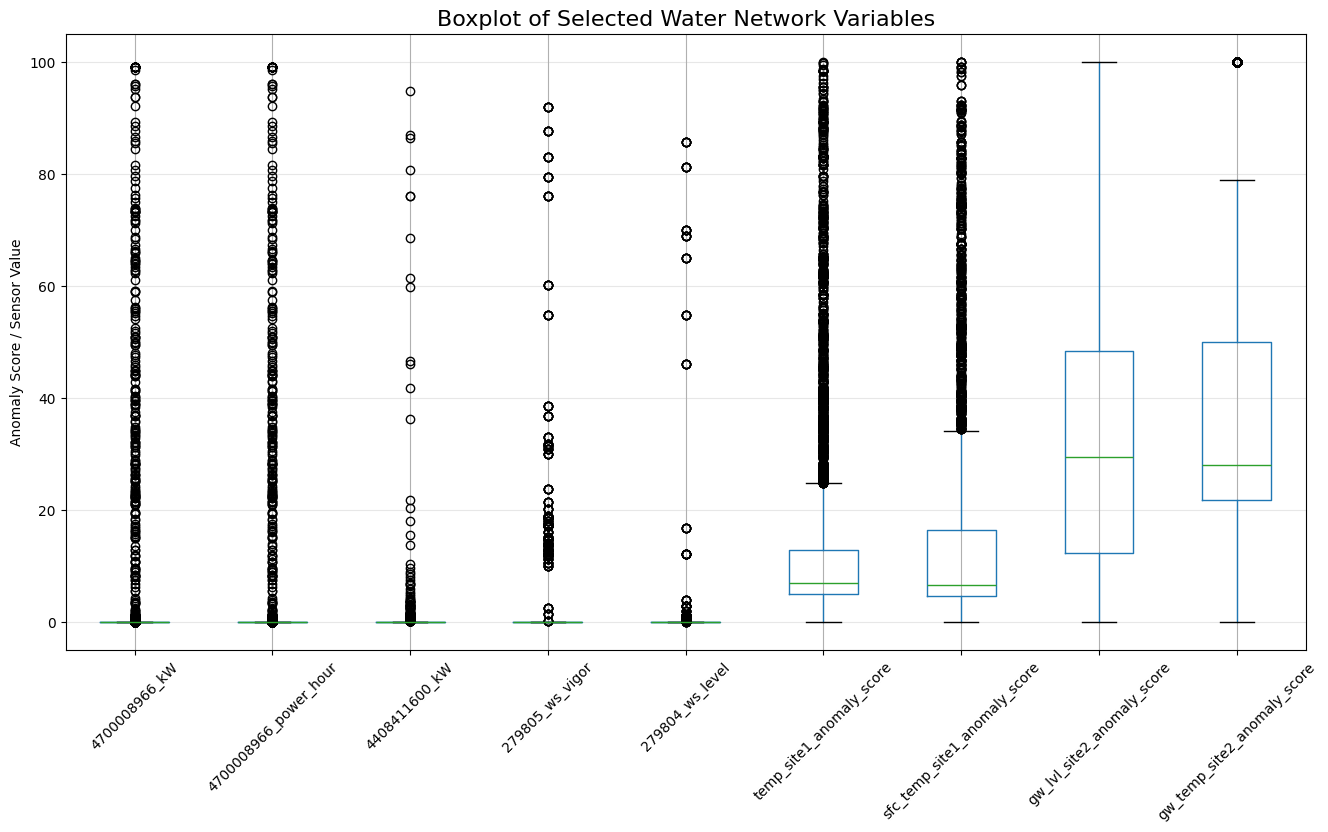

In [ ]:
# Boxplots for outlier analysis

plt.figure(figsize=(16, 8))

df_clean[eda_features].boxplot()

plt.title("Boxplot of Selected Water Network Variables", fontsize=16)
plt.ylabel("Anomaly Score / Sensor Value")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 13.4 Time-Series Trends
Plot selected variables in timestamp order to inspect temporal variation. Visible patterns are descriptive and do not establish causes.

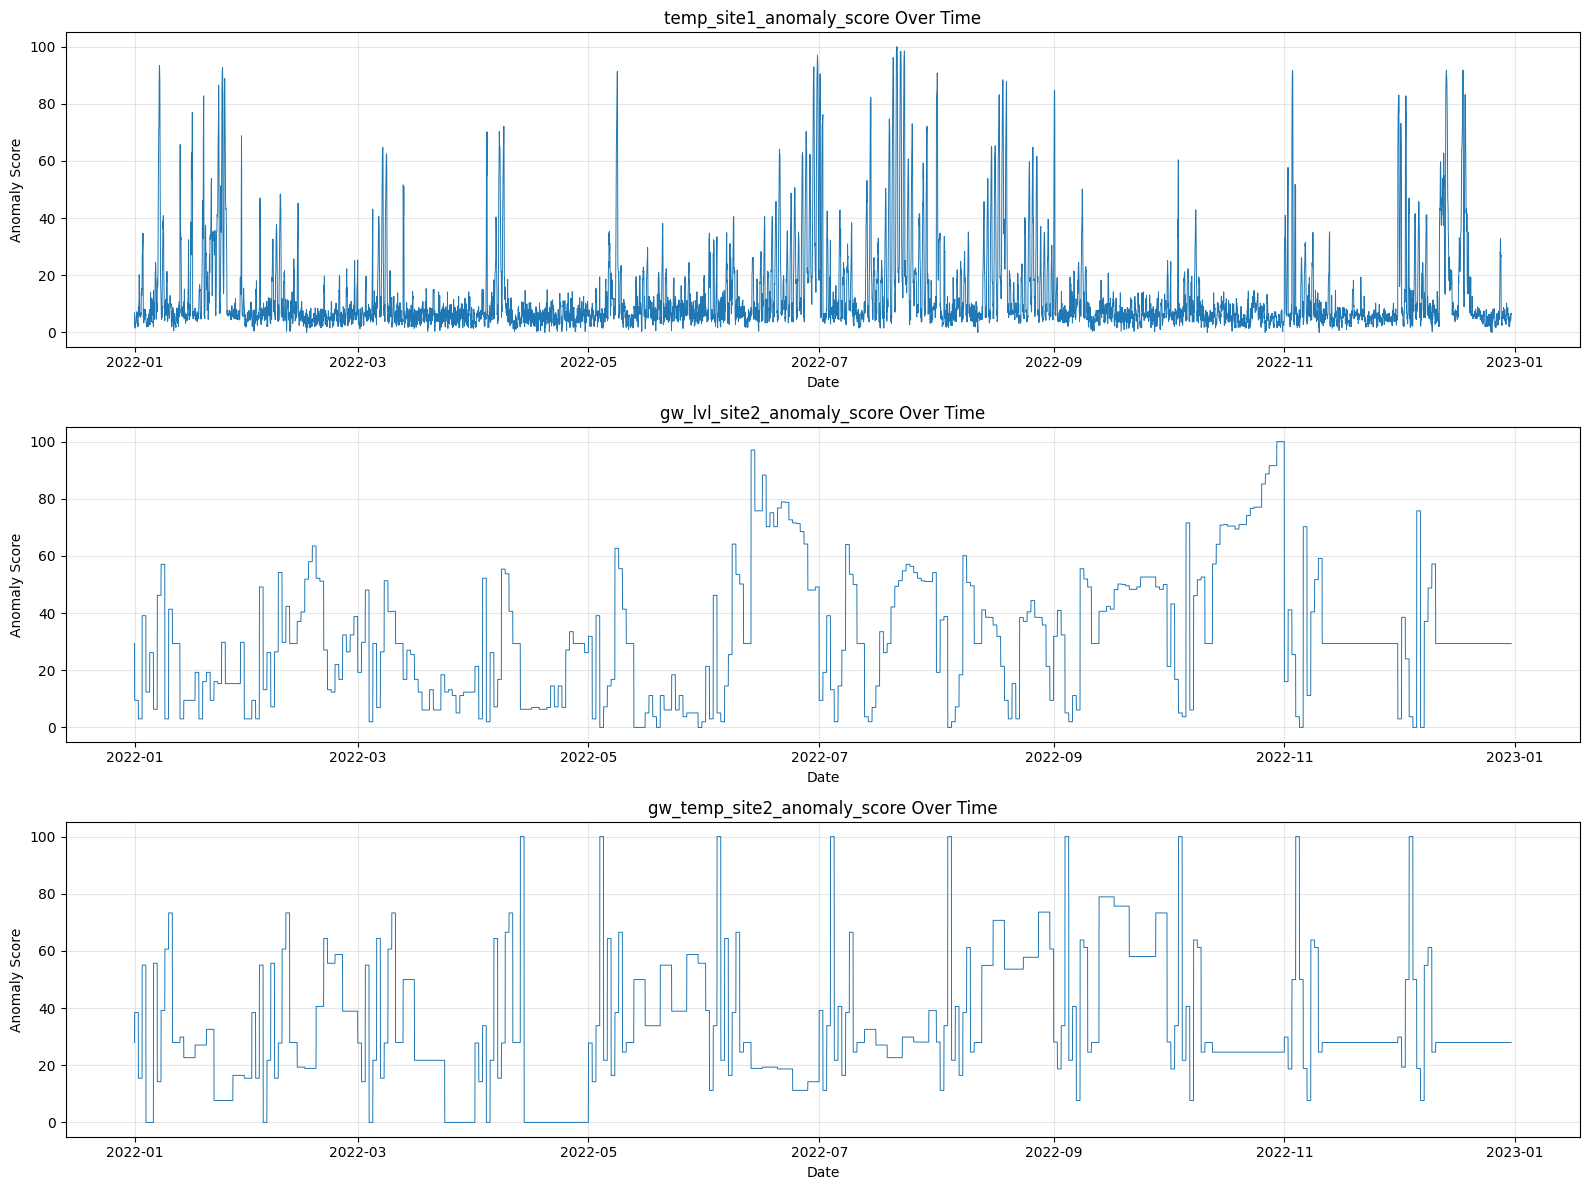

In [ ]:
# Cell 18: Time-Series Analysis

import matplotlib.pyplot as plt

# Sort the data by time
df_time = df_clean.sort_values("timestamp").copy()

# Select three environmental variables
time_features = [
    "temp_site1_anomaly_score",
    "gw_lvl_site2_anomaly_score",
    "gw_temp_site2_anomaly_score"
]

# Plot how these variables change over time
fig, axes = plt.subplots(3, 1, figsize=(16, 12))

for ax, col in zip(axes, time_features):
    ax.plot(df_time["timestamp"], df_time[col], linewidth=0.7)
    ax.set_title(f"{col} Over Time")
    ax.set_xlabel("Date")
    ax.set_ylabel("Anomaly Score")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 13.5 Compare Fault-Proximity Groups
Compare the selected feature averages between records labelled 0 and 1. The comparison is descriptive, not causal; features with different scales can be hard to compare in a single bar chart.

Average feature values by fault status:


fault_status,Fault-Proximity,Non-Fault-Proximity
4700008966_kW,1.58,0.27
4700008966_power_hour,1.58,0.25
4408411600_kW,0.17,0.06
279805_ws_vigor,1.16,0.05
279804_ws_level,0.42,0.22
temp_site1_anomaly_score,14.46,9.01
sfc_temp_site1_anomaly_score,14.54,9.96
gw_lvl_site2_anomaly_score,35.70,20.54
gw_temp_site2_anomaly_score,36.82,25.90


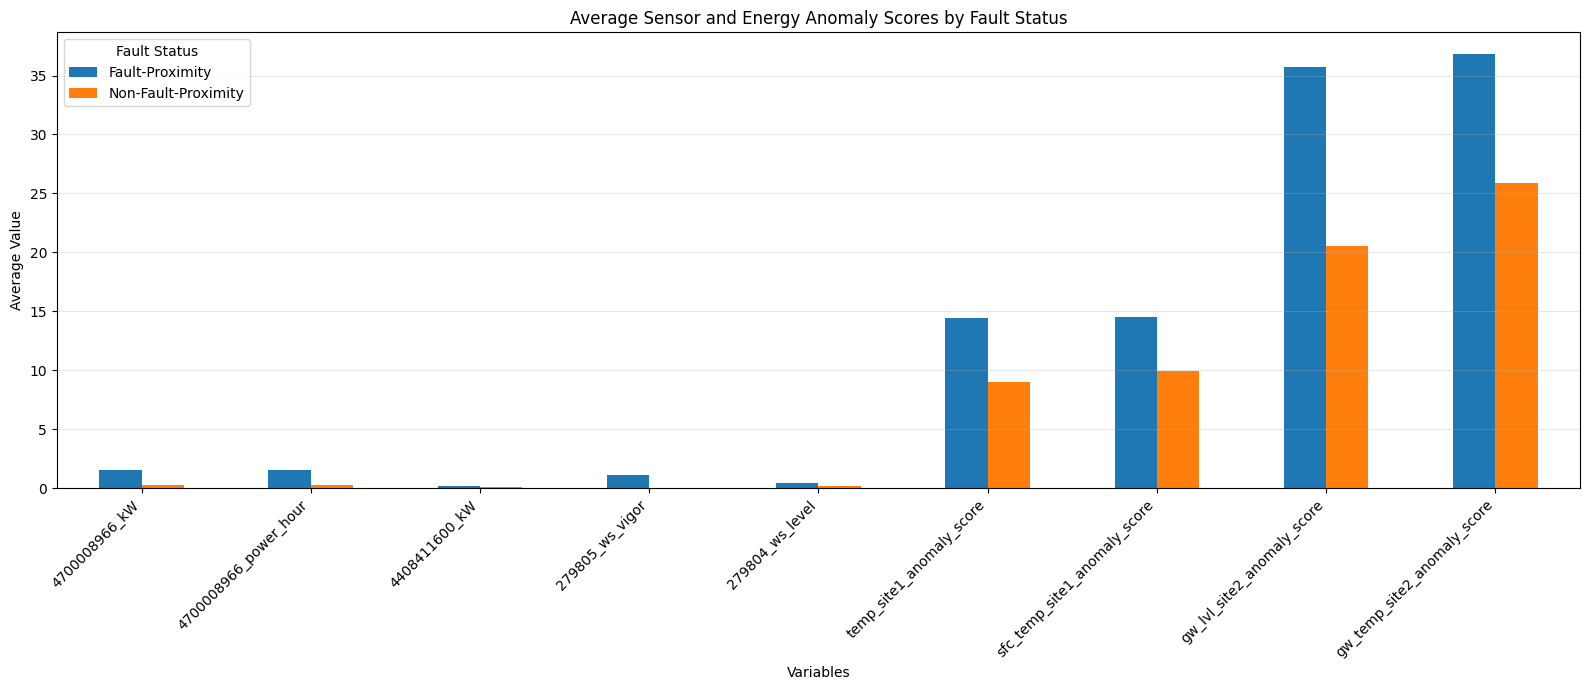

In [ ]:
# Cell 19: Fault vs Non-Fault Comparison

import pandas as pd
import matplotlib.pyplot as plt

# Create readable labels for the two groups
df_clean["fault_status"] = df_clean["fault_d7"].map({
    0: "Non-Fault-Proximity",
    1: "Fault-Proximity"
})

# Compare average scores across the two groups
comparison = df_clean.groupby("fault_status")[eda_features].mean().T

print("Average feature values by fault status:")
display(comparison.round(2))

# Visualize the comparison
comparison.plot(
    kind="bar",
    figsize=(16, 7)
)

plt.title("Average Sensor and Energy Anomaly Scores by Fault Status")
plt.xlabel("Variables")
plt.ylabel("Average Value")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Fault Status")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 13.6 Correlation Heatmap
Correlation describes pairwise linear association. It does not prove causation, and a near-zero correlation does not rule out nonlinear relationships.

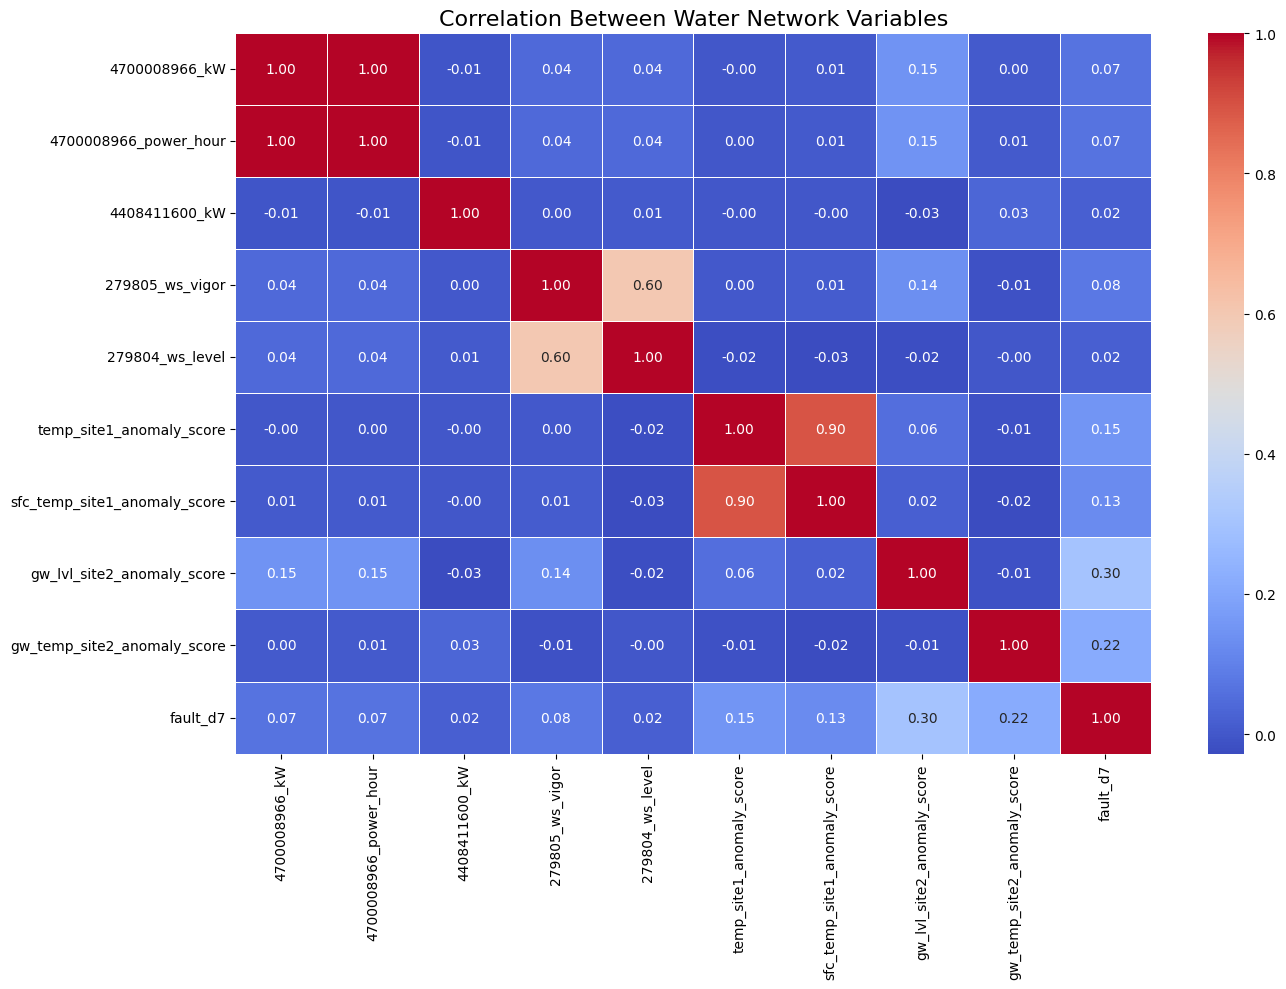

In [ ]:
#Cell 20: Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns for correlation analysis
correlation_features = eda_features + ["fault_d7"]

# Calculate correlation matrix
correlation_matrix = df_clean[correlation_features].corr()

# Display correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Water Network Variables", fontsize=16)
plt.tight_layout()
plt.show()


## 14. Feature Engineering
Extract hour, day, month, day of week, and weekend indicator from the timestamp. These are candidate predictors; their usefulness must be evaluated rather than assumed.

In [ ]:
#Feature Engineering

# Create a separate dataframe for feature engineering
df_model = df_clean.copy()

# Ensure timestamp is in datetime format
df_model["timestamp"] = pd.to_datetime(df_model["timestamp"])

# Extract time-based features
df_model["hour"] = df_model["timestamp"].dt.hour
df_model["day"] = df_model["timestamp"].dt.day
df_model["month"] = df_model["timestamp"].dt.month
df_model["day_of_week"] = df_model["timestamp"].dt.dayofweek

# Weekend indicator: 1 = Saturday/Sunday, 0 = weekday
df_model["is_weekend"] = (
    df_model["day_of_week"] >= 5
).astype(int)

# Display the new features
display(
    df_model[
        ["timestamp", "hour", "day", "month",
         "day_of_week", "is_weekend", "fault_d7"]
    ].head(10)
)

print("Original dataset shape:", df_clean.shape)
print("Feature-engineered dataset shape:", df_model.shape)


,timestamp,hour,day,month,day_of_week,is_weekend,fault_d7
0,2021-12-31 23:00:00,23,31,12,4,0,0
1,2022-01-01 00:00:00,0,1,1,5,1,0
2,2022-01-01 01:00:00,1,1,1,5,1,0
3,2022-01-01 02:00:00,2,1,1,5,1,0
4,2022-01-01 03:00:00,3,1,1,5,1,0
5,2022-01-01 04:00:00,4,1,1,5,1,0
6,2022-01-01 05:00:00,5,1,1,5,1,0
7,2022-01-01 06:00:00,6,1,1,5,1,0
8,2022-01-01 07:00:00,7,1,1,5,1,0
9,2022-01-01 08:00:00,8,1,1,5,1,0


Original dataset shape: (8737, 19)
Feature-engineered dataset shape: (8737, 24)


**Note:** The feature/target setup is consolidated in the next cell so there is one authoritative definition of `X`, `y`, and `feature_columns`. This avoids accidentally training on a different set of columns after editing the notebook.

## 15. Define Model Inputs and Target
Use numeric features as `X` and `fault_d7` as `y`. The target must never be included among the input features. The feature list is stored so the same columns can be supplied to the model later.

In [ ]:
# Define model inputs (X) and target (y) in one place
# Exclude the target from inputs to prevent direct target leakage.
# fault_status is a text-only plotting helper, so it is not selected as a numeric feature.
feature_columns = [
    col for col in df_model.select_dtypes(include="number").columns
    if col != "fault_d7"
]

X = df_model[feature_columns].copy()
y = df_model["fault_d7"].copy()

print("Number of records:", len(df_model))
print("Number of input features:", len(feature_columns))
print("\nInput features:")
print(feature_columns)

print("\nTarget label counts:")
print(y.value_counts().sort_index())

print("\nTarget label percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())


Number of records: 8737
Number of input features: 21

Input features:
['4700008966_kW', '4700008966_power_hour', '4408411600_kW', '4408411600_power_hour', '4608927500_kvar_hour', '238045_ws_temp', '279805_ws_vigor', '279804_ws_level', '279625_ws_temp', '279623_ws_vigor', '319235_ws_temp', '279831_ws_temp', 'temp_site1_anomaly_score', 'sfc_temp_site1_anomaly_score', 'gw_lvl_site2_anomaly_score', 'gw_temp_site2_anomaly_score', 'hour', 'day', 'month', 'day_of_week', 'is_weekend']

Target label counts:
fault_d7
0    2305
1    6432
Name: count, dtype: int64

Target label percentages:
fault_d7
0    26.38
1    73.62
Name: proportion, dtype: float64

Missing values in X: 0
Missing values in y: 0


## 16. Chronological Train/Test Split
Use the first 80% of records for training and the later 20% for testing. This better reflects forecasting on later observations than a random split. Note that the class balance changes over time, so report class-wise metrics.

In [ ]:
# Cell 23: Split Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(df_model["timestamp"].iloc[0], "to",
      df_model["timestamp"].iloc[split_index - 1])

print("\nTesting period:")
print(df_model["timestamp"].iloc[split_index], "to",
      df_model["timestamp"].iloc[-1])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 6989
Testing records: 1748

Training period:
2021-12-31 23:00:00 to 2022-10-19 03:00:00

Testing period:
2022-10-19 04:00:00 to 2022-12-30 23:00:00

Training target distribution:
fault_d7
1    0.708
0    0.292
Name: proportion, dtype: float64

Testing target distribution:
fault_d7
1    0.849
0    0.151
Name: proportion, dtype: float64


## 17. Model 1 — Logistic Regression
Train a scaled Logistic Regression baseline. Scaling helps because numeric inputs may have different ranges. `class_weight='balanced'` gives more weight to the minority class during fitting.

In [ ]:
#Cell 24: Train the Logistic Regression Model

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build and train Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

lr_model.fit(X_train, y_train)

# Predict labels for the test data
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")
print("Number of test predictions:", len(lr_predictions))


Logistic Regression model trained successfully!
Number of test predictions: 1748


## 18. Model 2 — Random Forest
Train a Random Forest with 100 trees and a depth limit. It can model nonlinear patterns and interactions, but it is not guaranteed to outperform the baseline.

In [ ]:
#Cell 25: Train the Random Forest Model

from sklearn.ensemble import RandomForestClassifier

# Build the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict labels for the test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("Number of test predictions:", len(rf_predictions))


Random Forest model trained successfully!
Number of test predictions: 1748


## 19. Model Evaluation
Compare accuracy, precision, recall, F1-score, and class-wise reports. Because the label distribution is imbalanced, interpret each class separately and do not select a model based on accuracy alone.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report
)
import pandas as pd

# Positive-class metrics refer to fault_d7 = 1.
# Balanced accuracy and macro-F1 give both classes equal importance.
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, lr_predictions),
        balanced_accuracy_score(y_test, rf_predictions)
    ],
    "Precision (class 1)": [
        precision_score(y_test, lr_predictions, pos_label=1, zero_division=0),
        precision_score(y_test, rf_predictions, pos_label=1, zero_division=0)
    ],
    "Recall (class 1)": [
        recall_score(y_test, lr_predictions, pos_label=1, zero_division=0),
        recall_score(y_test, rf_predictions, pos_label=1, zero_division=0)
    ],
    "F1 (class 1)": [
        f1_score(y_test, lr_predictions, pos_label=1, zero_division=0),
        f1_score(y_test, rf_predictions, pos_label=1, zero_division=0)
    ],
    "Macro F1": [
        f1_score(y_test, lr_predictions, average="macro", zero_division=0),
        f1_score(y_test, rf_predictions, average="macro", zero_division=0)
    ]
})

display(results.round(3))

print("\nLogistic Regression — class-wise report:")
print(classification_report(y_test, lr_predictions, labels=[0, 1],
                            target_names=["Outside proximity (0)", "Within proximity (1)"],
                            zero_division=0))

print("\nRandom Forest — class-wise report:")
print(classification_report(y_test, rf_predictions, labels=[0, 1],
                            target_names=["Outside proximity (0)", "Within proximity (1)"],
                            zero_division=0))

print("Interpretation reminder: these metrics evaluate the supplied fault-proximity label,")
print("not confirmed physical leak detection.")


,Model,Accuracy,Balanced Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),Macro F1
0,Logistic Regression,0.842,0.630,0.886,0.933,0.909,0.646
1,Random Forest,0.876,0.591,0.873,1.000,0.932,0.620



Logistic Regression — class-wise report:
                       precision    recall  f1-score   support

Outside proximity (0)       0.46      0.33      0.38       264
 Within proximity (1)       0.89      0.93      0.91      1484

             accuracy                           0.84      1748
            macro avg       0.68      0.63      0.65      1748
         weighted avg       0.82      0.84      0.83      1748


Random Forest — class-wise report:
                       precision    recall  f1-score   support

Outside proximity (0)       1.00      0.18      0.31       264
 Within proximity (1)       0.87      1.00      0.93      1484

             accuracy                           0.88      1748
            macro avg       0.94      0.59      0.62      1748
         weighted avg       0.89      0.88      0.84      1748

Interpretation reminder: these metrics evaluate the supplied fault-proximity label,
not confirmed physical leak detection.


### 19.1 Confusion Matrices
The diagonal contains correct predictions; off-diagonal cells show errors. For class 0, low recall means many non-fault-proximity records are incorrectly labelled 1.

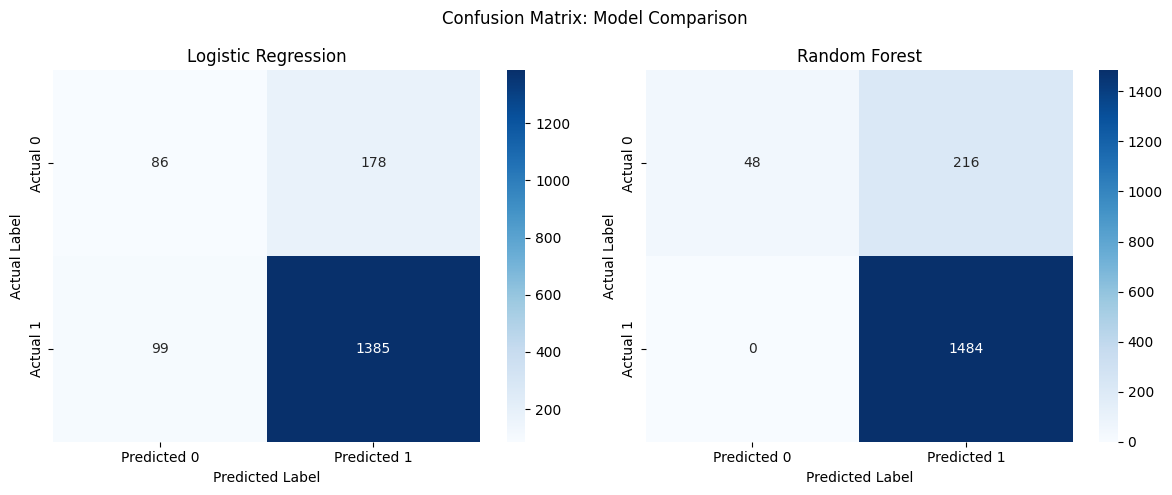

In [ ]:
#CONFUSION MATRICES

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Logistic Regression", lr_predictions),
    ("Random Forest", rf_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix: Model Comparison")
plt.tight_layout()
plt.show()


### 19.2 Random Forest Feature Importance
Feature importance indicates which variables the fitted Random Forest used most. It is not causal evidence and can be affected by correlated features.

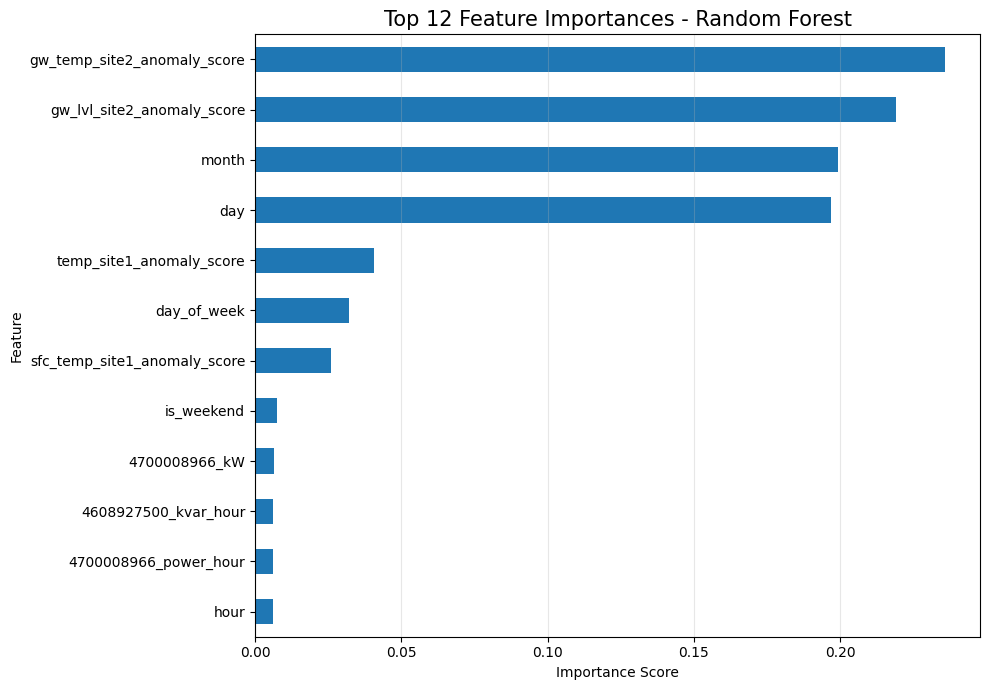

Top 12 Important Features:


,Importance
gw_temp_site2_anomaly_score,0.2360
gw_lvl_site2_anomaly_score,0.2192
month,0.1992
day,0.1968
temp_site1_anomaly_score,0.0405
day_of_week,0.0322
sfc_temp_site1_anomaly_score,0.0260
is_weekend,0.0075
4700008966_kW,0.0065
4608927500_kvar_hour,0.0063


In [ ]:
#Cell 28: Random Forest Feature Importance.

import pandas as pd
import matplotlib.pyplot as plt

# Calculate feature importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Select the top 12 features
top_features = importance.head(12).sort_values()

# Plot feature importance
plt.figure(figsize=(10, 7))
top_features.plot(kind="barh")

plt.title("Top 12 Feature Importances - Random Forest", fontsize=15)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Display the exact importance values
print("Top 12 Important Features:")
display(importance.head(12).to_frame("Importance").round(4))


### 19.3 Performance Comparison Chart
Compare the metrics visually. Include class-wise recall or macro-F1 in your presentation, not just the headline accuracy.

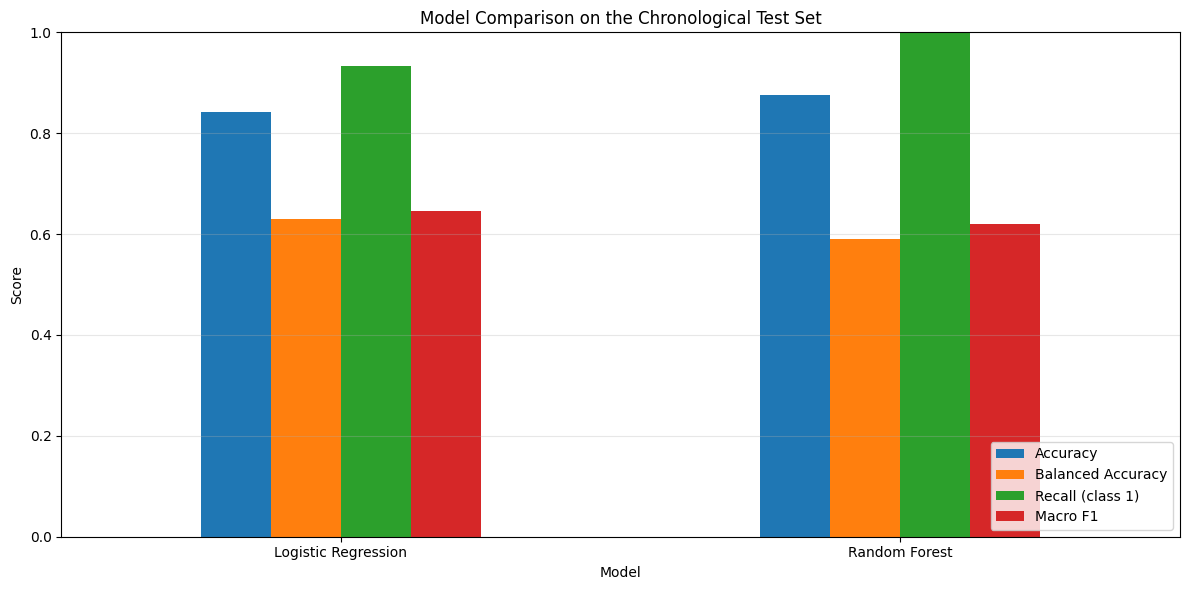

In [ ]:
# Compare metrics that summarize overall performance and class-1 detection.
metrics = ["Accuracy", "Balanced Accuracy", "Recall (class 1)", "Macro F1"]
results_plot = results.set_index("Model")[metrics]

results_plot.plot(kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0)
plt.title("Model Comparison on the Chronological Test Set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 20. Save Models to Google Drive
Mount Drive using the account selected in the authorization prompt. No email address needs to be hard-coded.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


### 20.1 Export the Trained Models
Save the fitted pipelines/models and exact feature names. Keep the library versions compatible when loading these files later.

In [ ]:

import os
import joblib

# Create a folder for the WaterWise project
save_dir = "/content/drive/MyDrive/WaterWise/models"
os.makedirs(save_dir, exist_ok=True)

# Save both trained models
joblib.dump(lr_model, os.path.join(save_dir, "logistic_regression.pkl"))
joblib.dump(rf_model, os.path.join(save_dir, "random_forest.pkl"))

# Save the feature column names
joblib.dump(feature_columns, os.path.join(save_dir, "feature_columns.pkl"))

print("Models saved successfully!")
print("Location:", save_dir)


Models saved successfully!
Location: /content/drive/MyDrive/WaterWise/models


## 23. Findings, Limitations, and Future Work

### Findings to report after rerunning
- The dataset contains **8,737 hourly records** over approximately one year.
- The target is imbalanced: about **73.6%** of records have `fault_d7 = 1` and **26.4%** have `fault_d7 = 0`.
- Two columns were removed because more than 40% of their values were missing; remaining numeric missing values were filled with their median.
- EDA includes distributions, boxplots, time-series trends, fault-proximity group comparison, and correlation analysis.
- Logistic Regression and Random Forest are compared on a chronological holdout set.

### Limitations
- The target means proximity to a labelled fault window, not a confirmed physical leak.
- The label distribution differs between training and testing periods, which can affect scores.
- Median imputation and feature importance have limitations; correlation is not causation.
- Time-derived features can help capture calendar patterns but do not establish fault causes.
- A single chronological split is one evaluation, not proof of general performance. Future work should test multiple time-based splits and investigate whether any source features are closely tied to the way `fault_d7` was constructed.

### Future enhancements
1. Add a Streamlit dashboard with dataset overview, interactive charts, and model comparison.
2. Add a user-facing sample prediction with a clear disclaimer that it predicts the dataset label.
3. Evaluate multiple chronological splits and tune the classification threshold using validation data.
4. Add data-drift monitoring and document the source, assumptions, and limitations.

### Suggested conclusion
**WaterWise demonstrates a complete data-analysis workflow—from data quality assessment and visualization to feature engineering and baseline classification—using real hourly water-network-related data. The goal is to explore patterns associated with a provided fault-proximity label, not to claim operational leak detection.**